In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
metadata = pd.read_csv("../../../data/processed/id_metadata.csv", sep="\t")
essentia = pd.read_parquet("../../../data/processed/essentia.parquet")
lyrics = pd.read_parquet("../../../data/processed/lyrics_tf_idf.parquet")
genres = pd.read_csv("../../../data/processed/id_genres_tf-idf.tsv", sep="\t")

In [3]:
metadata

,id,spotify_id,popularity,release,danceability,energy,key,mode,valence,tempo,duration_ms
0,0009fFIM1eYThaPg,3eObKIfHKJ1nAPh0wTxFCc,12.0,2009,0.635,0.746,6.0,1.0,0.548,110.973,229947
1,0010xmHR6UICBOYT,27szvF97Tu95GxN98N52fy,46.0,2013,0.591,0.513,7.0,0.0,0.263,172.208,325096
2,002Jyd0vN4HyCpqL,273lBFpxUCwisTpdnF9cVb,31.0,1974,0.319,0.925,2.0,1.0,0.658,157.630,285693
3,006TYKNjNxWjfKjy,1qZgergQ41vaD4zBf3AKXR,33.0,2017,0.432,0.979,7.0,1.0,0.162,90.008,332867
4,007LIJOPQ4Sb98qV,6rVxJ3sN3Cz40MSLavbG1K,19.0,2009,0.357,0.708,9.0,1.0,0.470,123.904,326067
...,...,...,...,...,...,...,...,...,...,...,...
109264,zzyyPUs7hC9Nz2e1,6IW5yPlWJYmXxRuuc7QkMx,36.0,2017,0.380,0.835,1.0,1.0,0.539,142.699,200880
109265,zzz0n04uuTUA7fNh,21pCToQdqcPi879auxjxKe,48.0,2014,0.572,0.503,6.0,0.0,0.553,103.215,262840
109266,zzzj3LYaZtYtbzSr,2SJ6FGmRPacKE9N4g4BRZU,21.0,2010,0.402,0.376,2.0,0.0,0.119,108.509,276507
109267,zzznMjZAKnJJXQSj,2ygfHXyt3gvyhvKrNJU61n,47.0,2017,0.532,0.977,10.0,0.0,0.966,116.527,224549


In [18]:
essentia.head()

,id,release,genre,lowlevel.average_loudness,lowlevel.barkbands.mean_0,lowlevel.barkbands.mean_1,lowlevel.barkbands.mean_2,lowlevel.barkbands.mean_3,lowlevel.barkbands.mean_4,lowlevel.barkbands.mean_5,...,tonal.thpcp_30,tonal.thpcp_31,tonal.thpcp_32,tonal.thpcp_33,tonal.thpcp_34,tonal.thpcp_35,tonal.tuning_diatonic_strength,tonal.tuning_equal_tempered_deviation,tonal.tuning_frequency,tonal.tuning_nontempered_energy_ratio
0,0009fFIM1eYThaPg,2009,pop,0.933530,0.003060,0.015665,0.004106,0.001265,0.001988,0.001152,...,0.752843,0.544830,0.394721,0.372330,0.422420,0.855395,0.563373,0.226941,434.193115,0.944264
1,0010xmHR6UICBOYT,2013,underground hip hop,0.985564,0.009209,0.078349,0.004850,0.001458,0.000622,0.000331,...,0.119888,0.325183,0.882466,0.917528,0.421067,0.563627,0.500238,0.263457,434.193115,0.981752
2,002Jyd0vN4HyCpqL,1974,hard rock,0.975591,0.000013,0.000334,0.001160,0.000701,0.002691,0.003497,...,0.170216,0.122699,0.124897,0.148278,0.170249,0.530251,0.584540,0.100636,443.828888,0.770219
3,006TYKNjNxWjfKjy,2017,symphonic metal,0.937591,0.002685,0.008301,0.001781,0.001958,0.004531,0.002717,...,0.407134,0.383419,0.502890,0.473931,0.413351,0.984334,0.607076,0.188990,434.193115,0.907491
4,007LIJOPQ4Sb98qV,2009,post-punk,0.974263,0.000033,0.002381,0.003582,0.008344,0.005149,0.001792,...,0.308227,0.296546,0.310534,0.374532,0.422366,0.864219,0.705242,0.097163,442.548920,0.794072


In [19]:
lyrics.head()

,id,release,genre,abl,accept,across,act,addict,afraid,age,...,yea,yeah,year,yellow,yes,yesterday,yet,yo,young,youth
0,0009fFIM1eYThaPg,2009,pop,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.009265,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0
1,0010xmHR6UICBOYT,2013,underground hip hop,0.0,0.0,0.000000,0.0,0.0,0.0,0.115873,...,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.119455,0.0,0.0
2,002Jyd0vN4HyCpqL,1974,hard rock,0.0,0.0,0.074979,0.0,0.0,0.0,0.000000,...,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0
3,006TYKNjNxWjfKjy,2017,symphonic metal,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0
4,007LIJOPQ4Sb98qV,2009,post-punk,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.000000,0.0,0.0,0.0,0.575963,0.057672,0.000000,0.0,0.0


In [20]:
genres.head()

,id,new weird america,flamenco,gospel,folk,breakbeat,jazz trumpet,funeral doom,underground hip hop,jazz metal,...,country rock,raw black metal,minimal wave,grime,synthpop,gothic rock,aggrotech,uk hip hop,cyberpunk,mashup
0,0009fFIM1eYThaPg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0010xmHR6UICBOYT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.888005,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,002Jyd0vN4HyCpqL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,006TYKNjNxWjfKjy,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,007LIJOPQ4Sb98qV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [54]:
label_counts = (genres.select_dtypes(include="number") > 0).sum(axis=1).value_counts().sort_index()

result = {n: count for n, count in label_counts.items()}

print(result)

{' genres 0': 27, ' genres 1': 33120, ' genres 2': 38315, ' genres 3': 26236, ' genres 4': 9266, ' genres 5': 1908, ' genres 6': 393, ' genres 7': 4}


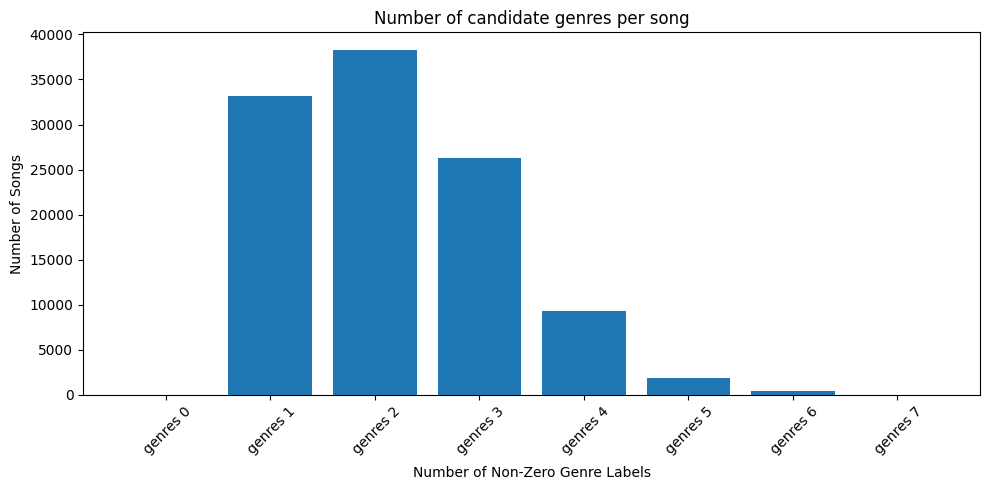

In [65]:
plt.figure(figsize=(10, 5))
plt.bar(*zip(*result.items()))
plt.xlabel("Number of Non-Zero Genre Labels")
plt.ylabel("Number of Songs")
plt.title("Number of candidate genres per song")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("plots/distribution_genres_per_song.png")
plt.show()